# Lab Program 2 — Hugging Face Hub, Convolution & Pooling in NumPy, and a CNN for CIFAR-10

**Course:** Deep Learning Lab — Self Learning / Continuous Evaluation

**Aim**
1. Introduce the **Hugging Face Hub**, **dataset loading** with 🤗 `datasets`, and **model cards**.
2. Implement **2-D convolution** and **max-pooling** from scratch using **NumPy**.
3. Explore the effect of **kernel size, stride and padding**.
4. Build and train a **basic CNN** for **CIFAR-10** image classification.

| Part | Topic |
|---|---|
| A | Hugging Face Hub, dataset loading, model cards |
| B | Convolution and max-pooling with NumPy (verified against PyTorch) |
| C | Kernel size, stride and padding experiments |
| D | Basic CNN on CIFAR-10 (PyTorch) |
| E | Writing a model card for our own CNN |

In [1]:
import time, random, warnings
warnings.filterwarnings("ignore", message="IProgress not found")
import datasets
datasets.disable_progress_bars()
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

device = ("cuda" if torch.cuda.is_available()
          else "mps" if torch.backends.mps.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| NumPy:", np.__version__, "| device:", device)

PyTorch: 2.15.0 | NumPy: 2.5.4 | device: mps


---
## Part A — The Hugging Face Hub

The [Hugging Face Hub](https://huggingface.co) is a platform that hosts **models**, **datasets** and **Spaces** (demo apps).
Every item lives in a **Git-based repository** (`owner/name`), so it is versioned, can be cloned, and has a commit history.

* **Models** — pretrained weights plus config files (e.g. `google/vit-base-patch16-224`).
* **Datasets** — data files plus a loading script / Parquet shards (e.g. `uoft-cs/cifar10`).
* **Spaces** — Gradio / Streamlit apps that demo a model.

Two Python libraries are used here:

* `huggingface_hub` — talk to the Hub: search, read metadata, download files, read/write model cards.
* `datasets` — download and load a dataset as an Arrow-backed `Dataset` object, with fast slicing, mapping and format conversion.

No login is required for reading public repositories.

### A.1 Searching the Hub with `HfApi`

In [2]:
from huggingface_hub import HfApi
api = HfApi()

print("Top 5 image-classification models by downloads:")
for m in api.list_models(pipeline_tag="image-classification", sort="downloads", limit=5):
    print(f"  {m.id:45s} downloads={m.downloads}")

print("\nDatasets matching 'cifar10':")
for d in api.list_datasets(search="cifar10", sort="downloads", limit=5):
    print(f"  {d.id:45s} downloads={d.downloads}")

Top 5 image-classification models by downloads:


  google/vit-base-patch16-224                   downloads=15279929
  timm/mobilenetv3_small_100.lamb_in1k          downloads=11042427
  prithivMLmods/Gender-Classifier-Mini          downloads=7097523
  timm/tf_efficientnetv2_s.in21k_ft_in1k        downloads=3626630
  timm/resnet18.a1_in1k                         downloads=1953064

Datasets matching 'cifar10':


  uoft-cs/cifar10                               downloads=341487
  uoft-cs/cifar100                              downloads=111145
  MIT-OL-AI-D/cifar-10-python                   downloads=16091
  xingslong/cifar-100-python                    downloads=9603
  spaicom-lab/semasia-cifar10                   downloads=6815


In [3]:
MODEL_ID = "google/vit-base-patch16-224"
info = api.model_info(MODEL_ID)
print("Model      :", info.id)
print("Task       :", info.pipeline_tag)
print("Library    :", info.library_name)
print("Tags       :", info.tags[:10])
print("Files in repo:")
for s in info.siblings:
    print("   -", s.rfilename)

Model      : google/vit-base-patch16-224
Task       : image-classification
Library    : transformers
Tags       : ['transformers', 'pytorch', 'tf', 'jax', 'safetensors', 'vit', 'image-classification', 'vision', 'dataset:imagenet-1k', 'dataset:imagenet-21k']
Files in repo:
   - .gitattributes
   - README.md
   - config.json
   - flax_model.msgpack
   - model.safetensors
   - preprocessor_config.json
   - pytorch_model.bin
   - tf_model.h5


### A.2 Model cards

A **model card** is the `README.md` of a model repository. It has two parts:

1. **YAML metadata** at the top (between `---` lines): license, tags, datasets used, evaluation metrics, …
   The Hub uses this to make the model searchable and to show the evaluation widget.
2. **Markdown body**: model description, intended uses & limitations, training data, training procedure,
   evaluation results, bias / ethical considerations and citation.

Model cards (Mitchell et al., 2019) document *what a model is for, how it was built, and where it fails*,
which is essential for responsible reuse. `huggingface_hub.ModelCard` loads and parses them.

In [4]:
from huggingface_hub import ModelCard, DatasetCard

card = ModelCard.load(MODEL_ID)
print("=== Structured metadata (card.data) ===")
print(card.data.to_yaml())
print("=== First 1200 characters of the card body ===")
print(card.text[:1200])

=== Structured metadata (card.data) ===
datasets:
- imagenet-1k
- imagenet-21k
license: apache-2.0
tags:
- vision
- image-classification
widget:
- src: https://huggingface.co/datasets/mishig/sample_images/resolve/main/tiger.jpg
  example_title: Tiger
- src: https://huggingface.co/datasets/mishig/sample_images/resolve/main/teapot.jpg
  example_title: Teapot
- src: https://huggingface.co/datasets/mishig/sample_images/resolve/main/palace.jpg
  example_title: Palace
=== First 1200 characters of the card body ===

# Vision Transformer (base-sized model) 

Vision Transformer (ViT) model pre-trained on ImageNet-21k (14 million images, 21,843 classes) at resolution 224x224, and fine-tuned on ImageNet 2012 (1 million images, 1,000 classes) at resolution 224x224. It was introduced in the paper [An Image is Worth 16x16 Words: Transformers for Image Recognition at Scale](https://arxiv.org/abs/2010.11929) by Dosovitskiy et al. and first released in [this repository](https://github.com/google-resear

In [5]:
ds_card = DatasetCard.load("uoft-cs/cifar10")
meta = ds_card.data.to_dict()
print("Dataset card metadata keys:", list(meta.keys()))
print("License:", meta.get("license"), "| Task categories:", meta.get("task_categories"))
print()
print(ds_card.text[:800])

Dataset card metadata keys: ['annotations_creators', 'language_creators', 'language', 'license', 'multilinguality', 'size_categories', 'source_datasets', 'task_categories', 'task_ids', 'paperswithcode_id', 'pretty_name', 'dataset_info', 'configs']
License: ['unknown'] | Task categories: ['image-classification']


# Dataset Card for CIFAR-10

## Table of Contents
- [Dataset Description](#dataset-description)
  - [Dataset Summary](#dataset-summary)
  - [Supported Tasks and Leaderboards](#supported-tasks-and-leaderboards)
  - [Languages](#languages)
- [Dataset Structure](#dataset-structure)
  - [Data Instances](#data-instances)
  - [Data Fields](#data-fields)
  - [Data Splits](#data-splits)
- [Dataset Creation](#dataset-creation)
  - [Curation Rationale](#curation-rationale)
  - [Source Data](#source-data)
  - [Annotations](#annotations)
  - [Personal and Sensitive Information](#personal-and-sensitive-information)
- [Considerations for Using the Data](#considerations-for-using-the-data)
 

### A.3 Loading a dataset with 🤗 `datasets`

`load_dataset(repo_id)` downloads the data once (cached in `~/.cache/huggingface`) and returns a `DatasetDict`
with one `Dataset` per split. Each `Dataset` has typed **features** — here an `Image` column and a `ClassLabel` column.

In [6]:
from datasets import load_dataset

cifar = load_dataset("uoft-cs/cifar10")
print(cifar)
print("\nFeatures:", cifar["train"].features)

CLASSES = cifar["train"].features["label"].names
print("\nClass names:", CLASSES)

DatasetDict({
    train: Dataset({
        features: ['img', 'label'],
        num_rows: 50000
    })
    test: Dataset({
        features: ['img', 'label'],
        num_rows: 10000
    })
})

Features: {'img': Image(mode=None, decode=True), 'label': ClassLabel(names=['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck'])}

Class names: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


One example: {'img': ('PngImageFile', (32, 32)), 'label': ('int', 0)}
Images per class (train): {'airplane': 5000, 'automobile': 5000, 'bird': 5000, 'cat': 5000, 'deer': 5000, 'dog': 5000, 'frog': 5000, 'horse': 5000, 'ship': 5000, 'truck': 5000}


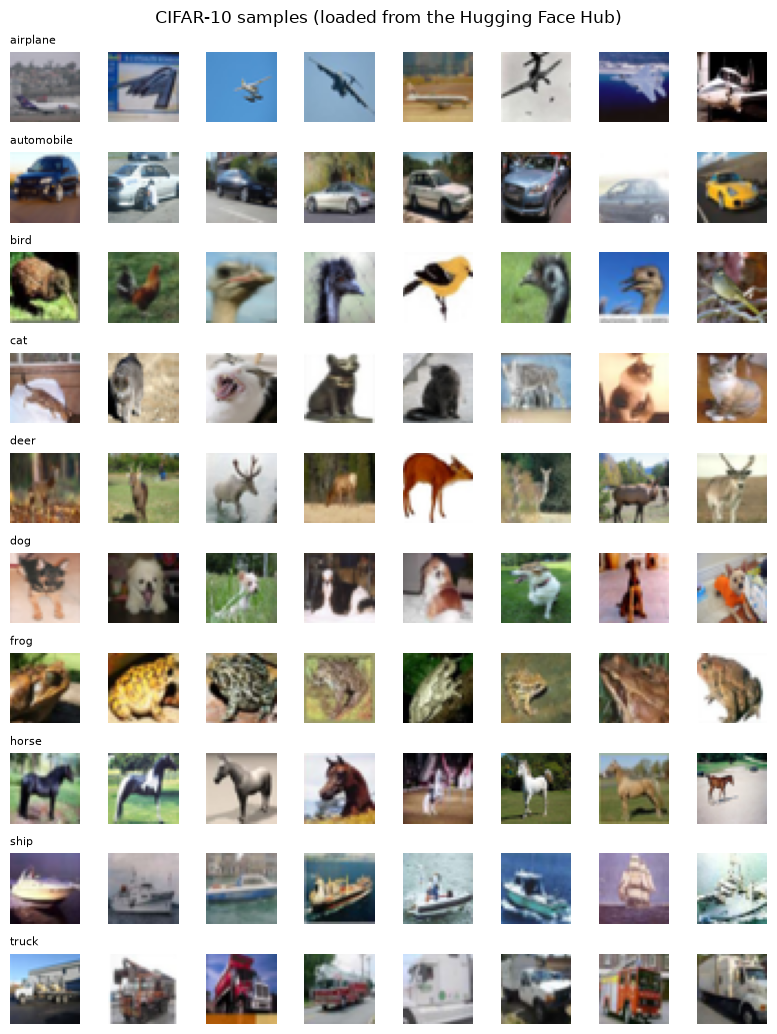

In [7]:
sample = cifar["train"][0]
print("One example:", {k: (type(v).__name__, getattr(v, 'size', v)) for k, v in sample.items()})

# Class balance of the training split
counts = np.bincount(np.asarray(list(cifar["train"]["label"])), minlength=10)
print("Images per class (train):", dict(zip(CLASSES, counts.tolist())))

# Show a grid of examples, one row per class
fig, axes = plt.subplots(10, 8, figsize=(8, 10.5))
labels = np.asarray(list(cifar["train"].select(range(5000))["label"]))
for c in range(10):
    idx = np.where(labels == c)[0][:8]
    for j, i in enumerate(idx):
        ax = axes[c, j]
        ax.imshow(cifar["train"][int(i)]["img"]); ax.axis("off")
    axes[c, 0].set_title(CLASSES[c], fontsize=8, loc="left")
plt.suptitle("CIFAR-10 samples (loaded from the Hugging Face Hub)")
plt.tight_layout(); plt.show()

Useful `datasets` operations: `select`, `filter`, `map`, `train_test_split`, `with_format("numpy"|"torch")`
and `streaming=True` (iterate without downloading everything).

In [8]:
small = cifar["train"].select(range(1000))
cats  = small.filter(lambda ex: ex["label"] == CLASSES.index("cat"))
print("1000-image subset ->", len(cats), "cats")

split = small.train_test_split(test_size=0.2, seed=SEED)
print("train/test split of the subset:", {k: len(v) for k, v in split.items()})

arr = cifar["test"].with_format("numpy")[:4]["img"]
print("with_format('numpy') ->", type(arr), arr.shape, arr.dtype)

stream = load_dataset("uoft-cs/cifar10", split="test", streaming=True)
first = next(iter(stream))
print("Streaming mode first label:", CLASSES[first["label"]])

1000-image subset -> 87 cats
train/test split of the subset: {'train': 800, 'test': 200}
with_format('numpy') -> <class 'numpy.ndarray'> (4, 32, 32, 3) uint8


Streaming mode first label: cat


---
## Part B — Convolution and Max-Pooling from scratch in NumPy

### B.1 Definitions

For an input $X$ of shape $(C_{in}, H, W)$, a filter bank $K$ of shape $(C_{out}, C_{in}, k_h, k_w)$, bias $b$,
stride $s$ and zero-padding $p$, the (deep-learning style, i.e. *cross-correlation*) convolution is

$$
Y[f, i, j] = b_f + \sum_{c=0}^{C_{in}-1}\sum_{u=0}^{k_h-1}\sum_{v=0}^{k_w-1} X_p[c,\; i\,s + u,\; j\,s + v]\; K[f, c, u, v]
$$

where $X_p$ is $X$ zero-padded by $p$ pixels on every side. The output size along each axis is

$$
H_{out} = \left\lfloor \frac{H + 2p - k_h}{s} \right\rfloor + 1, \qquad
W_{out} = \left\lfloor \frac{W + 2p - k_w}{s} \right\rfloor + 1 .
$$

**Max-pooling** with window $k$ and stride $s$ takes the maximum over each window, independently per channel:
$Y[c,i,j] = \max_{u,v<k} X[c,\; i s+u,\; j s+v]$. It has **no learnable parameters**.

Two implementations are given: a readable **loop** version and a fast vectorised **im2col** version.

In [9]:
def out_size(n, k, s=1, p=0):
    # Output length of a conv/pool along one axis.
    return (n + 2 * p - k) // s + 1


def pad2d(x, p):
    # Zero-pad the last two axes of x by p pixels on each side.
    if p == 0:
        return x
    return np.pad(x, [(0, 0)] * (x.ndim - 2) + [(p, p), (p, p)], mode="constant")


def conv2d_loops(x, w, b=None, stride=1, padding=0):
    # Naive convolution.  x: (C_in, H, W)   w: (C_out, C_in, kh, kw)   ->  (C_out, H_out, W_out)
    C_in, H, W = x.shape
    C_out, C_in_w, kh, kw = w.shape
    assert C_in == C_in_w, "channel mismatch"
    xp = pad2d(x, padding)
    Ho, Wo = out_size(H, kh, stride, padding), out_size(W, kw, stride, padding)
    y = np.zeros((C_out, Ho, Wo), dtype=np.float64)
    for f in range(C_out):                      # every filter
        for i in range(Ho):                     # every output row
            for j in range(Wo):                 # every output column
                r, c = i * stride, j * stride
                patch = xp[:, r:r + kh, c:c + kw]           # (C_in, kh, kw) receptive field
                y[f, i, j] = np.sum(patch * w[f])
        if b is not None:
            y[f] += b[f]
    return y


def maxpool2d_loops(x, k=2, stride=None, padding=0):
    # Naive max-pooling.  x: (C, H, W)  ->  (C, H_out, W_out)
    stride = stride or k
    C, H, W = x.shape
    xp = np.pad(x, [(0, 0), (padding, padding), (padding, padding)], constant_values=-np.inf)
    Ho, Wo = out_size(H, k, stride, padding), out_size(W, k, stride, padding)
    y = np.zeros((C, Ho, Wo), dtype=x.dtype)
    for c in range(C):
        for i in range(Ho):
            for j in range(Wo):
                r, cc = i * stride, j * stride
                y[c, i, j] = xp[c, r:r + k, cc:cc + k].max()
    return y

### B.2 Vectorised version (im2col)

Loops are slow in Python. The standard trick is **im2col**: extract every $k_h\times k_w$ patch into a column, so the
whole convolution becomes **one matrix multiplication** — exactly how cuDNN / BLAS-based frameworks do it.
`numpy.lib.stride_tricks.sliding_window_view` gives the patches without copying memory. This version also
supports a **batch** dimension $(N, C, H, W)$.

In [10]:
from numpy.lib.stride_tricks import sliding_window_view


def conv2d(x, w, b=None, stride=1, padding=0):
    # Vectorised convolution.  x: (N, C_in, H, W) or (C_in, H, W);  w: (C_out, C_in, kh, kw)
    squeeze = x.ndim == 3
    if squeeze:
        x = x[None]
    kh, kw = w.shape[2:]
    xp = pad2d(x, padding)
    # windows: (N, C_in, H_out', W_out', kh, kw) at stride 1, then subsample for the stride
    win = sliding_window_view(xp, (kh, kw), axis=(2, 3))[:, :, ::stride, ::stride]
    # contract over C_in, kh, kw  ->  (N, H_out, W_out, C_out)  ->  (N, C_out, H_out, W_out)
    y = np.einsum("nchwij,fcij->nfhw", win, w, optimize=True)
    if b is not None:
        y = y + b[None, :, None, None]
    return y[0] if squeeze else y


def maxpool2d(x, k=2, stride=None, padding=0):
    # Vectorised max-pooling over the last two axes (any leading dims).
    stride = stride or k
    if padding:
        x = np.pad(x, [(0, 0)] * (x.ndim - 2) + [(padding, padding)] * 2, constant_values=-np.inf)
    win = sliding_window_view(x, (k, k), axis=(-2, -1))[..., ::stride, ::stride, :, :]
    return win.max(axis=(-2, -1))


def relu(x):
    return np.maximum(x, 0)

### B.3 Correctness check against PyTorch

We compare our outputs to `torch.nn.functional.conv2d` / `max_pool2d` on random data for many
(kernel, stride, padding) combinations.

In [11]:
rng = np.random.default_rng(SEED)
print(f"{'k':>2} {'s':>2} {'p':>2} | {'out shape':>14} | max|loops-torch|  max|im2col-torch|  max|pool-torch|")
for k, s, p in [(1, 1, 0), (3, 1, 0), (3, 1, 1), (3, 2, 1), (5, 1, 2), (5, 2, 0), (7, 3, 3)]:
    x = rng.standard_normal((3, 17, 19))
    w = rng.standard_normal((4, 3, k, k))
    b = rng.standard_normal(4)
    ref = F.conv2d(torch.tensor(x)[None], torch.tensor(w), torch.tensor(b), stride=s, padding=p)[0].numpy()
    y1 = conv2d_loops(x, w, b, s, p)
    y2 = conv2d(x, w, b, s, p)
    pk = max(k, 2)
    pref = F.max_pool2d(torch.tensor(x)[None], pk, s, min(p, pk // 2))[0].numpy()
    py = maxpool2d(x, pk, s, min(p, pk // 2))
    assert y1.shape == y2.shape == ref.shape and py.shape == pref.shape
    print(f"{k:>2} {s:>2} {p:>2} | {str(y1.shape):>14} | {np.abs(y1-ref).max():15.2e}  "
          f"{np.abs(y2-ref).max():17.2e}  {np.abs(py-pref).max():14.2e}")
print("\nAll implementations match PyTorch ✔")

 k  s  p |      out shape | max|loops-torch|  max|im2col-torch|  max|pool-torch|
 1  1  0 |    (4, 17, 19) |        4.44e-16           0.00e+00        0.00e+00
 3  1  0 |    (4, 15, 17) |        5.33e-15           3.55e-15        0.00e+00
 3  1  1 |    (4, 17, 19) |        5.33e-15           3.55e-15        0.00e+00
 3  2  1 |     (4, 9, 10) |        3.55e-15           3.55e-15        0.00e+00
 5  1  2 |    (4, 17, 19) |        1.42e-14           7.11e-15        0.00e+00
 5  2  0 |      (4, 7, 8) |        1.78e-14           7.11e-15        0.00e+00
 7  3  3 |      (4, 6, 7) |        2.49e-14           1.42e-14        0.00e+00

All implementations match PyTorch ✔


In [12]:
# Speed comparison on a realistic layer: batch of 8 CIFAR images, 16 filters 3x3, same padding
xb = rng.standard_normal((8, 3, 32, 32))
wb = rng.standard_normal((16, 3, 3, 3))

t = time.perf_counter(); _ = [conv2d_loops(xi, wb, padding=1) for xi in xb]; t_loop = time.perf_counter() - t
t = time.perf_counter(); _ = conv2d(xb, wb, padding=1);                     t_vec  = time.perf_counter() - t
print(f"loops : {t_loop*1000:8.1f} ms\nim2col: {t_vec*1000:8.1f} ms   ->  {t_loop/t_vec:.0f}x faster")

loops :    186.0 ms
im2col:      0.6 ms   ->  326x faster


### B.4 Applying hand-crafted kernels to a real CIFAR-10 image

Classic image-processing kernels show what a single convolution can detect. A CNN *learns* kernels like these
(and many more) automatically in its first layer.

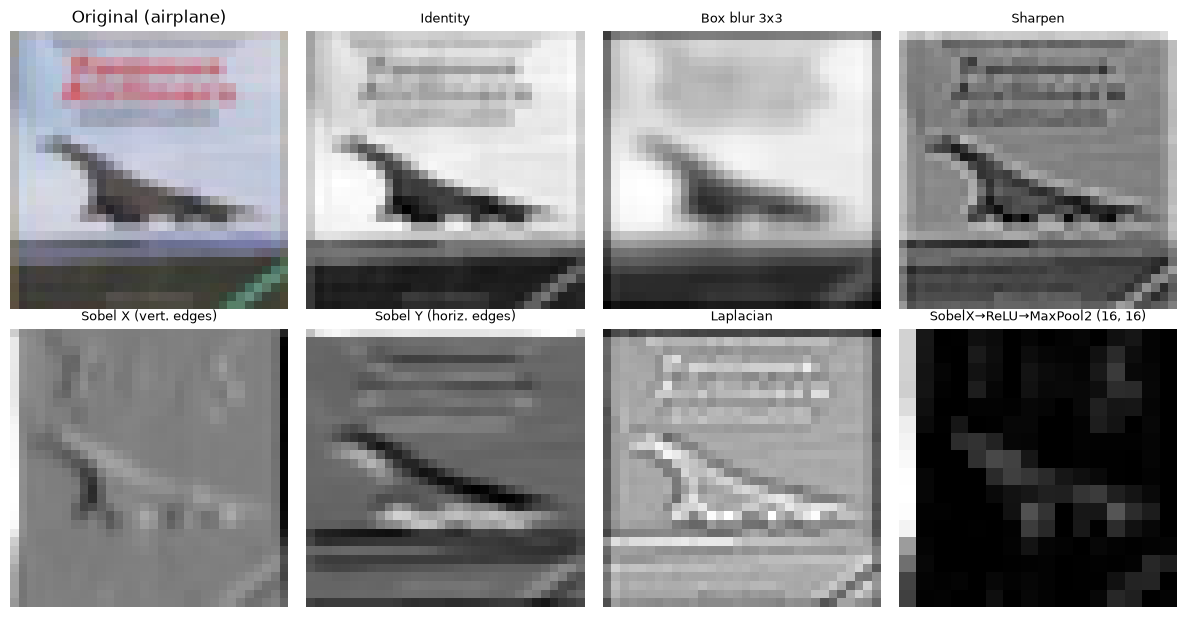

In [13]:
img = np.asarray(cifar["test"][3]["img"], dtype=np.float64) / 255.0       # (32, 32, 3)
gray = img.mean(axis=2)[None]                                             # (1, 32, 32)

kernels = {
    "Identity":       np.array([[0, 0, 0], [0, 1, 0], [0, 0, 0]]),
    "Box blur 3x3":   np.ones((3, 3)) / 9,
    "Sharpen":        np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]]),
    "Sobel X (vert. edges)": np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]]),
    "Sobel Y (horiz. edges)": np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]]),
    "Laplacian":      np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]]),
}

fig, axes = plt.subplots(2, 4, figsize=(12, 6.2))
axes = axes.ravel()
axes[0].imshow(img); axes[0].set_title(f"Original ({CLASSES[cifar['test'][3]['label']]})")
for ax, (name, k) in zip(axes[1:], kernels.items()):
    out = conv2d(gray, k[None, None].astype(float), padding=1)[0]
    ax.imshow(out, cmap="gray"); ax.set_title(name, fontsize=9)
# conv -> ReLU -> maxpool pipeline on the Sobel-X response
feat = maxpool2d(relu(conv2d(gray, kernels["Sobel X (vert. edges)"][None, None].astype(float), padding=1)), 2)
axes[7].imshow(feat[0], cmap="gray"); axes[7].set_title(f"SobelX→ReLU→MaxPool2 {feat.shape[1:]}", fontsize=9)
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

In [14]:
# Max-pooling on a tiny example, step by step
x = np.array([[1, 3, 2, 4],
              [5, 6, 1, 2],
              [7, 2, 9, 0],
              [3, 8, 4, 6]], dtype=float)[None]
print("Input:\n", x[0])
print("\nMaxPool k=2, s=2:\n", maxpool2d(x, 2, 2)[0])
print("\nMaxPool k=2, s=1 (overlapping):\n", maxpool2d(x, 2, 1)[0])
print("\nMaxPool k=3, s=1:\n", maxpool2d(x, 3, 1)[0])

Input:
 [[1. 3. 2. 4.]
 [5. 6. 1. 2.]
 [7. 2. 9. 0.]
 [3. 8. 4. 6.]]

MaxPool k=2, s=2:
 [[6. 4.]
 [8. 9.]]

MaxPool k=2, s=1 (overlapping):
 [[6. 6. 4.]
 [7. 9. 9.]
 [8. 9. 9.]]

MaxPool k=3, s=1:
 [[9. 9.]
 [9. 9.]]


---
## Part C — Exploring kernel size, stride and padding

| Hyper-parameter | Effect on output size | Other effects |
|---|---|---|
| **Kernel size** $k$ ↑ | shrinks output by $k-1$ (without padding) | larger receptive field, more parameters ($k^2 C_{in} C_{out}$), more compute |
| **Stride** $s$ ↑ | divides output size by ≈ $s$ | down-sampling, less compute, may skip information |
| **Padding** $p$ ↑ | grows output by $2p$ | keeps border information; $p=(k-1)/2$ with $s=1$ gives **"same"** output size |

### C.1 Output-size table (formula vs. our implementation)

In [15]:
H = 32
rows = []
for k in (1, 3, 5, 7):
    for s in (1, 2, 3):
        for p in sorted({0, (k - 1) // 2}):
            formula = out_size(H, k, s, p)
            actual = conv2d(np.zeros((1, H, H)), np.zeros((1, 1, k, k)), stride=s, padding=p).shape[-1]
            assert formula == actual
            rows.append((k, s, p, formula, k * k * 3 * 16 + 16))
print(f"Input 32x32x3 -> 16 filters\n{'kernel':>6} {'stride':>6} {'pad':>4} {'output':>8} {'#params':>8}")
for k, s, p, o, n in rows:
    tag = "  <- 'same'" if (s == 1 and o == H) else ""
    print(f"{k:>6} {s:>6} {p:>4} {f'{o}x{o}':>8} {n:>8}{tag}")

Input 32x32x3 -> 16 filters
kernel stride  pad   output  #params
     1      1    0    32x32       64  <- 'same'
     1      2    0    16x16       64
     1      3    0    11x11       64
     3      1    0    30x30      448
     3      1    1    32x32      448  <- 'same'
     3      2    0    15x15      448
     3      2    1    16x16      448
     3      3    0    10x10      448
     3      3    1    11x11      448
     5      1    0    28x28     1216
     5      1    2    32x32     1216  <- 'same'
     5      2    0    14x14     1216
     5      2    2    16x16     1216
     5      3    0    10x10     1216
     5      3    2    11x11     1216
     7      1    0    26x26     2368
     7      1    3    32x32     2368  <- 'same'
     7      2    0    13x13     2368
     7      2    3    16x16     2368
     7      3    0      9x9     2368
     7      3    3    11x11     2368


### C.2 Visual effect of kernel size (box blur) — larger kernels average over a wider neighbourhood

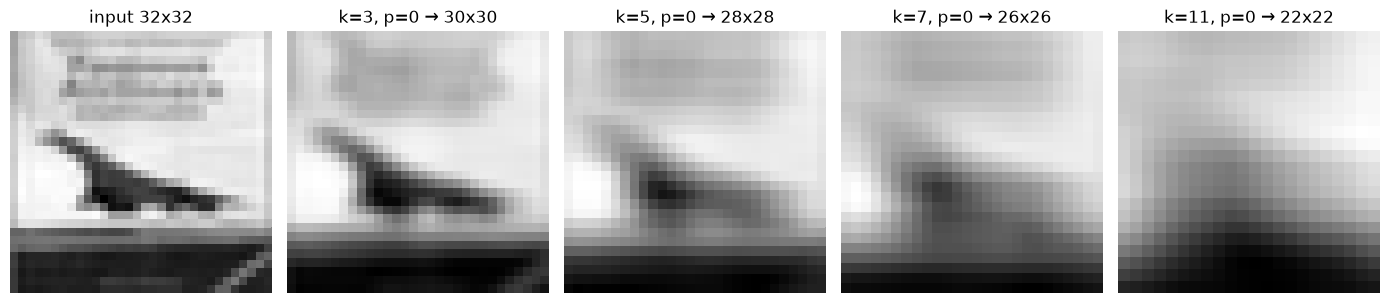

In [16]:
fig, axes = plt.subplots(1, 5, figsize=(14, 3.2))
axes[0].imshow(gray[0], cmap="gray"); axes[0].set_title("input 32x32")
for ax, k in zip(axes[1:], (3, 5, 7, 11)):
    out = conv2d(gray, np.ones((1, 1, k, k)) / k**2, padding=0)[0]
    ax.imshow(out, cmap="gray"); ax.set_title(f"k={k}, p=0 → {out.shape[0]}x{out.shape[1]}")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

### C.3 Visual effect of stride — the output is down-sampled

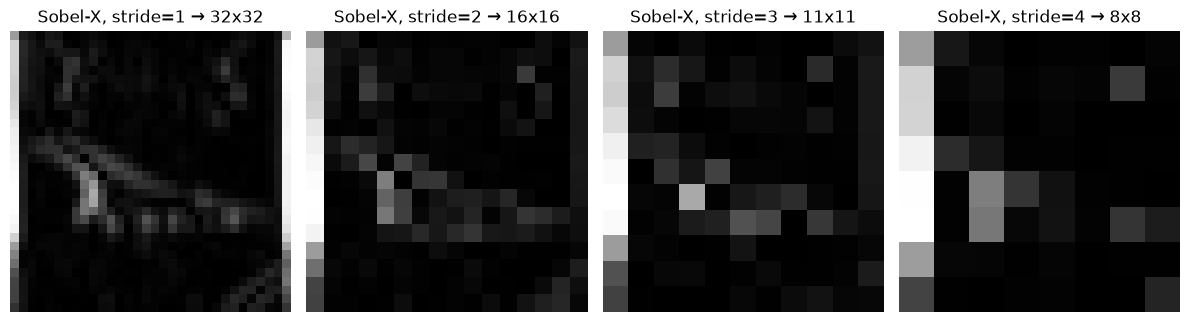

In [17]:
sob = kernels["Sobel X (vert. edges)"][None, None].astype(float)
fig, axes = plt.subplots(1, 4, figsize=(12, 3.2))
for ax, s in zip(axes, (1, 2, 3, 4)):
    out = conv2d(gray, sob, stride=s, padding=1)[0]
    ax.imshow(np.abs(out), cmap="gray"); ax.set_title(f"Sobel-X, stride={s} → {out.shape[0]}x{out.shape[1]}")
    ax.axis("off")
plt.tight_layout(); plt.show()

### C.4 Visual effect of padding

Without padding the border pixels take part in fewer windows and the map shrinks every layer.
With zero padding the size is preserved but an artificial edge appears at the border (zeros next to bright pixels).

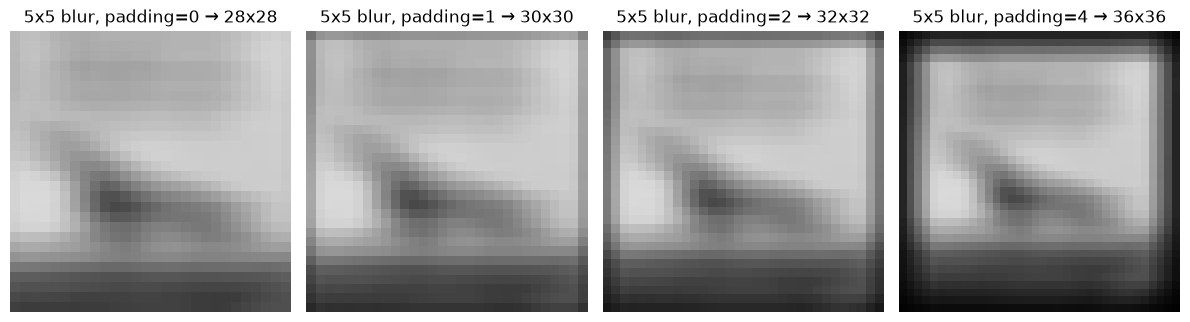

Map size after n stacked 3x3 convolutions (stride 1):
n        : [0, 1, 2, 3, 4, 5, 6, 7, 8]
padding=0: [32, 30, 28, 26, 24, 22, 20, 18, 16]
padding=1: [32, 32, 32, 32, 32, 32, 32, 32, 32]


In [18]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3.4))
for ax, p in zip(axes, (0, 1, 2, 4)):
    out = conv2d(gray, np.ones((1, 1, 5, 5)) / 25, padding=p)[0]
    ax.imshow(out, cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"5x5 blur, padding={p} → {out.shape[0]}x{out.shape[1]}"); ax.axis("off")
plt.tight_layout(); plt.show()

# How fast a 32x32 map shrinks through stacked 3x3 convs with and without padding
print("Map size after n stacked 3x3 convolutions (stride 1):")
print("n        :", list(range(0, 9)))
print("padding=0:", [out_size(32, 3, 1, 0) - 2 * (n - 1) if n else 32 for n in range(9)])
print("padding=1:", [32] * 9)

### C.5 Receptive field

Stacking layers grows the region of the input that one output unit "sees". For layers with kernel $k_l$ and stride $s_l$:
$RF_l = RF_{l-1} + (k_l - 1)\prod_{i<l} s_i$. Two stacked 3×3 convs see 5×5 and three see 7×7 —
with fewer parameters than a single 7×7 conv ($3\cdot 9C^2 = 27C^2$ vs $49C^2$). This is why VGG-style
networks use small 3×3 kernels, and why pooling / stride quickly enlarge the receptive field.

In [19]:
def receptive_field(layers):
    rf, jump = 1, 1
    for k, s in layers:
        rf += (k - 1) * jump
        jump *= s
    return rf

configs = {
    "1 x conv3":                         [(3, 1)],
    "2 x conv3":                         [(3, 1)] * 2,
    "3 x conv3":                         [(3, 1)] * 3,
    "1 x conv7":                         [(7, 1)],
    "conv3, conv3, pool2 (our block)":   [(3, 1), (3, 1), (2, 2)],
    "3 blocks of our CNN":               [(3, 1), (3, 1), (2, 2)] * 3,
}
for name, L in configs.items():
    print(f"{name:35s} receptive field = {receptive_field(L)} px")

1 x conv3                           receptive field = 3 px
2 x conv3                           receptive field = 5 px
3 x conv3                           receptive field = 7 px
1 x conv7                           receptive field = 7 px
conv3, conv3, pool2 (our block)     receptive field = 6 px
3 blocks of our CNN                 receptive field = 36 px


---
## Part D — A basic CNN for CIFAR-10

**Dataset:** 60 000 colour images of size 32×32 in 10 classes (50 000 train / 10 000 test), loaded from the Hub in Part A.

**Architecture** (VGG-style, three conv blocks):

```
Input 3x32x32
[Conv3x3(32) → BN → ReLU] x2 → MaxPool2 → Dropout   → 32x16x16
[Conv3x3(64) → BN → ReLU] x2 → MaxPool2 → Dropout   → 64x8x8
[Conv3x3(128)→ BN → ReLU] x2 → MaxPool2 → Dropout   → 128x4x4
Flatten → Linear(2048,256) → ReLU → Dropout → Linear(256,10)
```

All convolutions use $k=3, s=1, p=1$ ("same"), so only pooling reduces the spatial size — directly applying Part C.

### D.1 Data preparation
The HF images are converted once to a NumPy array, normalised with the per-channel training mean/std, and moved to
the device. Training uses light **data augmentation** (random crop with 4-pixel padding + horizontal flip),
done on-device on whole batches for speed.

In [20]:
def to_tensor(split):
    d = cifar[split].with_format("numpy")
    x = torch.from_numpy(np.stack(d["img"])).permute(0, 3, 1, 2).float() / 255.0   # (N,3,32,32)
    y = torch.from_numpy(np.asarray(d["label"])).long()
    return x, y

t0 = time.perf_counter()
Xtr, ytr = to_tensor("train")
Xte, yte = to_tensor("test")
mean = Xtr.mean(dim=(0, 2, 3), keepdim=True)
std = Xtr.std(dim=(0, 2, 3), keepdim=True)
Xtr, Xte = ((Xtr - mean) / std).to(device), ((Xte - mean) / std).to(device)
ytr, yte = ytr.to(device), yte.to(device)
print(f"train {tuple(Xtr.shape)}  test {tuple(Xte.shape)}  ({time.perf_counter()-t0:.1f}s)")
print("channel mean:", mean.flatten().numpy().round(4), " std:", std.flatten().numpy().round(4))


def augment(x):
    # Random crop (pad 4, reflect) + random horizontal flip, on a whole batch.
    n = x.size(0)
    flip = torch.rand(n, device=x.device) < 0.5
    x = torch.where(flip[:, None, None, None], x.flip(3), x)
    xp = F.pad(x, (4, 4, 4, 4), mode="reflect")
    i, j = np.random.randint(0, 9, size=2)          # one offset per batch keeps it fast & simple
    return xp[:, :, i:i + 32, j:j + 32]

train (50000, 3, 32, 32)  test (10000, 3, 32, 32)  (11.4s)
channel mean: [0.4914 0.4822 0.4465]  std: [0.247  0.2435 0.2616]


### D.2 Model

In [21]:
class BasicCNN(nn.Module):
    def __init__(self, num_classes=10, p_drop=0.25):
        super().__init__()

        def block(cin, cout):
            return nn.Sequential(
                nn.Conv2d(cin, cout, kernel_size=3, stride=1, padding=1), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
                nn.Conv2d(cout, cout, kernel_size=3, stride=1, padding=1), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
                nn.MaxPool2d(kernel_size=2, stride=2),
                nn.Dropout(p_drop),
            )

        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128))
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(128 * 4 * 4, 256), nn.ReLU(inplace=True), nn.Dropout(0.5), nn.Linear(256, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


model = BasicCNN().to(device)
print(model)
n_params = sum(p.numel() for p in model.parameters())
print(f"\nTrainable parameters: {n_params:,}")

# Trace the feature-map shape through the network
x = torch.zeros(1, 3, 32, 32, device=device)
for name, layer in list(model.features.named_children()) + [("classifier", model.classifier)]:
    x = layer(x)
    print(f"after {name:>10}: {tuple(x.shape)}")

BasicCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU(inplace=True)
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (7): Dropout(p=0.25, inplace=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_run

after          0: (1, 32, 16, 16)
after          1: (1, 64, 8, 8)
after          2: (1, 128, 4, 4)
after classifier: (1, 10)


### D.3 Training

* Loss: cross-entropy (with label smoothing 0.1)
* Optimiser: SGD, momentum 0.9, Nesterov, weight-decay 5e-4
* Schedule: One-Cycle learning rate (max 0.1)
* Batch size 128

In [22]:
EPOCHS = 15
BATCH = 128

criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = torch.optim.SGD(model.parameters(), lr=0.05, momentum=0.9, nesterov=True, weight_decay=5e-4)
steps_per_epoch = (len(Xtr) + BATCH - 1) // BATCH
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=0.1, epochs=EPOCHS, steps_per_epoch=steps_per_epoch)


@torch.no_grad()
def evaluate(X, Y, bs=1000):
    model.eval()
    loss, correct, preds = 0.0, 0, []
    for i in range(0, len(X), bs):
        out = model(X[i:i + bs])
        loss += F.cross_entropy(out, Y[i:i + bs], reduction="sum").item()
        p = out.argmax(1); preds.append(p)
        correct += (p == Y[i:i + bs]).sum().item()
    return loss / len(X), correct / len(X), torch.cat(preds)


history = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}
t_start = time.perf_counter()
for epoch in range(1, EPOCHS + 1):
    model.train()
    perm = torch.randperm(len(Xtr), device=device)
    run_loss, run_correct = 0.0, 0
    for i in range(0, len(Xtr), BATCH):
        idx = perm[i:i + BATCH]
        xb, yb = augment(Xtr[idx]), ytr[idx]
        out = model(xb)
        loss = criterion(out, yb)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step(); scheduler.step()
        run_loss += loss.item() * len(idx)
        run_correct += (out.argmax(1) == yb).sum().item()
    tr_loss, tr_acc = run_loss / len(Xtr), run_correct / len(Xtr)
    te_loss, te_acc, _ = evaluate(Xte, yte)
    for k, v in zip(history, (tr_loss, tr_acc, te_loss, te_acc)):
        history[k].append(v)
    print(f"epoch {epoch:2d}/{EPOCHS} | train loss {tr_loss:.3f} acc {tr_acc*100:5.2f}% | "
          f"test loss {te_loss:.3f} acc {te_acc*100:5.2f}% | {time.perf_counter()-t_start:6.0f}s")
train_time = time.perf_counter() - t_start

epoch  1/15 | train loss 1.797 acc 38.67% | test loss 1.256 acc 56.18% |     17s


epoch  2/15 | train loss 1.563 acc 52.51% | test loss 1.154 acc 59.74% |     35s


epoch  3/15 | train loss 1.428 acc 59.78% | test loss 0.934 acc 68.32% |     52s


epoch  4/15 | train loss 1.290 acc 66.24% | test loss 0.914 acc 69.09% |     71s


epoch  5/15 | train loss 1.206 acc 70.49% | test loss 0.756 acc 75.51% |     89s


epoch  6/15 | train loss 1.149 acc 73.23% | test loss 0.798 acc 73.11% |    107s


... (5 outputs left out)

epoch 12/15 | train loss 0.968 acc 81.27% | test loss 0.500 acc 84.54% |    229s


epoch 13/15 | train loss 0.936 acc 82.69% | test loss 0.460 acc 85.96% |    250s


epoch 14/15 | train loss 0.898 acc 84.39% | test loss 0.431 acc 87.18% |    271s


epoch 15/15 | train loss 0.879 acc 85.38% | test loss 0.421 acc 87.55% |    292s


### D.4 Results

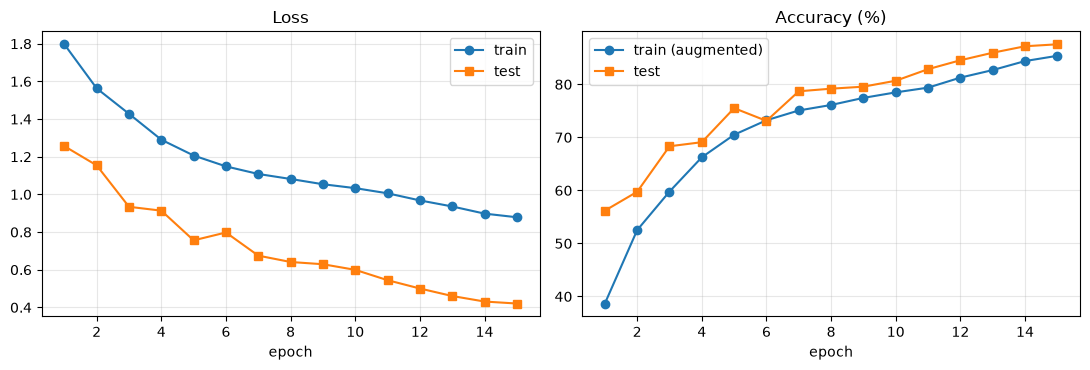

Final test accuracy: 87.55%   (test loss 0.421, training time 4.9 min)


In [23]:
ep = range(1, EPOCHS + 1)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
a1.plot(ep, history["train_loss"], "o-", label="train"); a1.plot(ep, history["test_loss"], "s-", label="test")
a1.set_title("Loss"); a1.set_xlabel("epoch"); a1.legend(); a1.grid(alpha=.3)
a2.plot(ep, np.array(history["train_acc"]) * 100, "o-", label="train (augmented)")
a2.plot(ep, np.array(history["test_acc"]) * 100, "s-", label="test")
a2.set_title("Accuracy (%)"); a2.set_xlabel("epoch"); a2.legend(); a2.grid(alpha=.3)
plt.tight_layout(); plt.show()

test_loss, test_acc, test_pred = evaluate(Xte, yte)
print(f"Final test accuracy: {test_acc*100:.2f}%   (test loss {test_loss:.3f}, training time {train_time/60:.1f} min)")

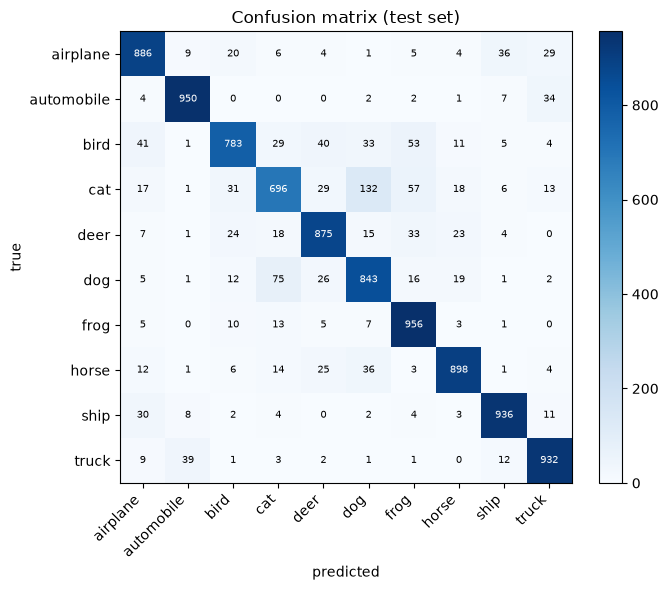

Per-class accuracy:
  frog          95.6%
  automobile    95.0%
  ship          93.6%
  truck         93.2%
  horse         89.8%
  airplane      88.6%
  deer          87.5%
  dog           84.3%
  bird          78.3%
  cat           69.6%


In [24]:
yt, yp = yte.cpu().numpy(), test_pred.cpu().numpy()
cm = np.zeros((10, 10), dtype=int)
np.add.at(cm, (yt, yp), 1)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(10), CLASSES, rotation=45, ha="right"); ax.set_yticks(range(10), CLASSES)
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title("Confusion matrix (test set)")
for i in range(10):
    for j in range(10):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7, color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.colorbar(im, fraction=0.046); plt.tight_layout(); plt.show()

per_class = cm.diagonal() / cm.sum(1)
print("Per-class accuracy:")
for c, a in sorted(zip(CLASSES, per_class), key=lambda t: -t[1]):
    print(f"  {c:12s} {a*100:5.1f}%")

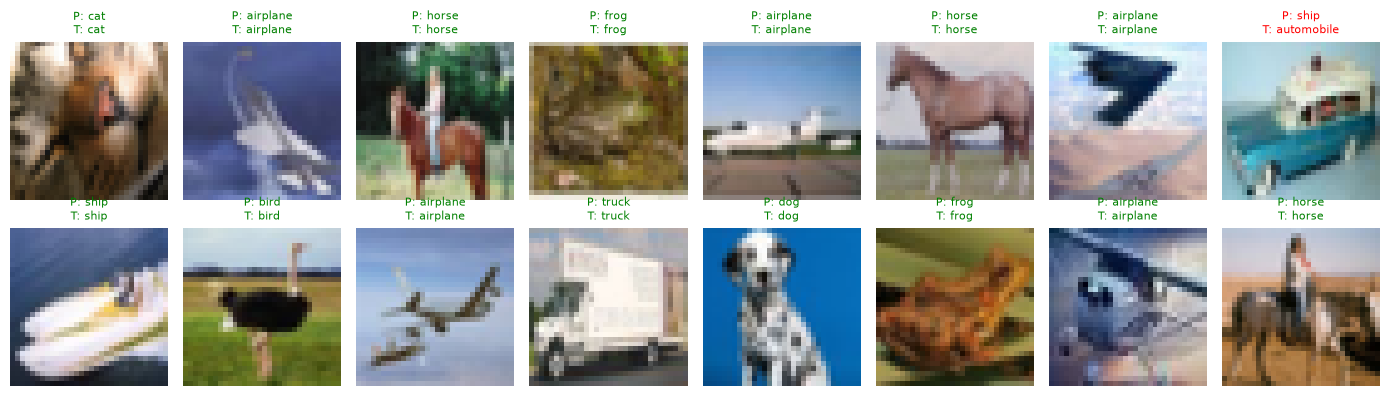

In [25]:
# Sample predictions (green = correct, red = wrong)
raw = cifar["test"]
idx = np.random.default_rng(1).choice(len(raw), 16, replace=False)
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for ax, i in zip(axes.ravel(), idx):
    ax.imshow(raw[int(i)]["img"]); ax.axis("off")
    ok = yp[i] == yt[i]
    ax.set_title(f"P: {CLASSES[yp[i]]}\nT: {CLASSES[yt[i]]}", fontsize=8, color="green" if ok else "red")
plt.tight_layout(); plt.show()

### D.5 What did the first layer learn?

The 32 learned 3×3×3 filters of the first convolution, and their feature maps for one test image —
compare them with the hand-crafted edge / blur kernels from Part B.

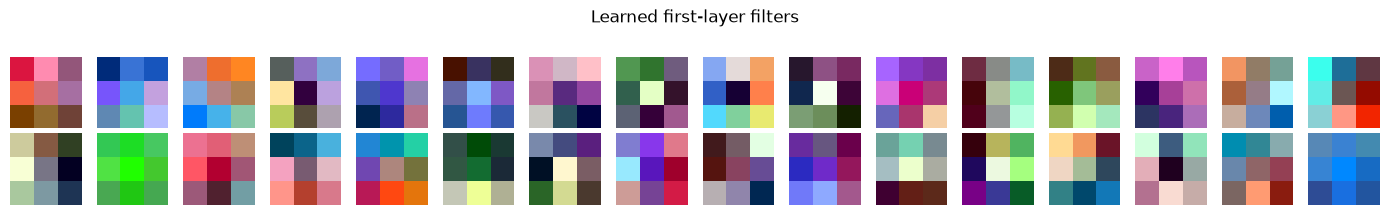

max |NumPy conv - PyTorch conv| on trained weights: 8.344650268554688e-07


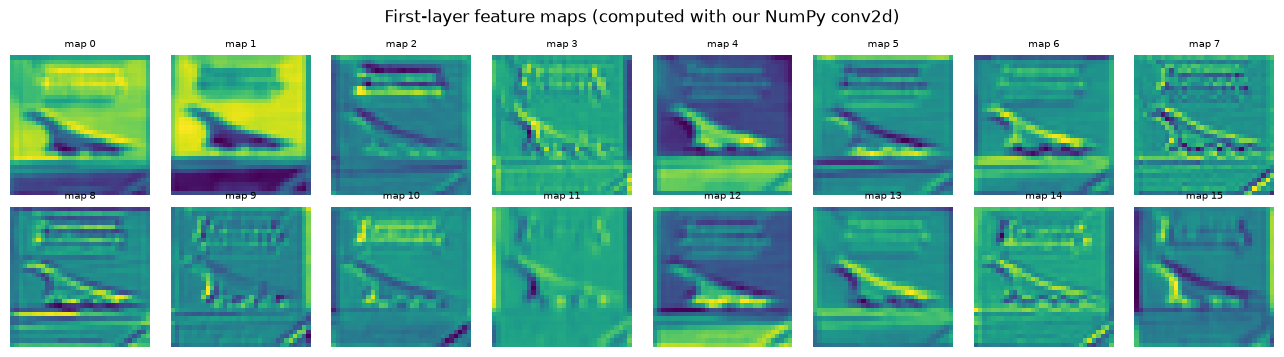

In [26]:
w1 = model.features[0][0].weight.detach().cpu().numpy()          # (32, 3, 3, 3)
fig, axes = plt.subplots(2, 16, figsize=(14, 2.2))
for f, ax in enumerate(axes.ravel()):
    k = w1[f].transpose(1, 2, 0); k = (k - k.min()) / (k.max() - k.min() + 1e-8)
    ax.imshow(k); ax.axis("off")
plt.suptitle("Learned first-layer filters"); plt.tight_layout(); plt.show()

# Our NumPy conv reproduces the first layer of the trained PyTorch model exactly
x0 = Xte[3:4].cpu().numpy()
b1 = model.features[0][0].bias.detach().cpu().numpy()
np_maps = conv2d(x0, w1, b1, stride=1, padding=1)[0]
with torch.no_grad():
    pt_maps = model.features[0][0](Xte[3:4]).cpu().numpy()[0]
print("max |NumPy conv - PyTorch conv| on trained weights:", float(np.abs(np_maps - pt_maps).max()))

fig, axes = plt.subplots(2, 8, figsize=(13, 3.6))
for f, ax in enumerate(axes.ravel()):
    ax.imshow(np_maps[f], cmap="viridis"); ax.axis("off"); ax.set_title(f"map {f}", fontsize=7)
plt.suptitle("First-layer feature maps (computed with our NumPy conv2d)"); plt.tight_layout(); plt.show()

---
## Part E — A model card for our CNN

Using `huggingface_hub.ModelCard` we write a proper model card (YAML metadata + Markdown) for the trained model,
filled in with the real evaluation results. It is saved locally as `MODEL_CARD.md`; it could be pushed to the Hub
with `card.push_to_hub("username/cifar10-basic-cnn")` after `huggingface-cli login` (not done here).

In [27]:
from huggingface_hub import ModelCardData

card_data = ModelCardData(
    language="en", license="mit", library_name="pytorch",
    tags=["image-classification", "cnn", "cifar10", "deep-learning-lab"],
    datasets=["uoft-cs/cifar10"], metrics=["accuracy"],
    model_name="cifar10-basic-cnn",
    eval_results=None,
)
per_class_md = "\n".join(f"| {c} | {a*100:.1f}% |" for c, a in zip(CLASSES, per_class))
content = f'''---
{card_data.to_yaml()}
model-index:
- name: cifar10-basic-cnn
  results:
  - task: {{type: image-classification, name: Image Classification}}
    dataset: {{name: CIFAR-10, type: uoft-cs/cifar10, split: test}}
    metrics:
    - {{type: accuracy, value: {test_acc:.4f}, name: Test accuracy}}
---

# cifar10-basic-cnn

A small VGG-style convolutional neural network ({n_params:,} parameters) trained from scratch on CIFAR-10
as part of Deep Learning Lab Program 2.

## Model description
Three blocks of `[Conv3x3 → BatchNorm → ReLU] x2 → MaxPool2 → Dropout(0.25)` with 32 / 64 / 128 channels,
followed by `Linear(2048, 256) → ReLU → Dropout(0.5) → Linear(256, 10)`. All convolutions use stride 1 and padding 1.

## Intended uses & limitations
* **Intended use:** teaching / demonstration of CNN fundamentals on 32×32 images of the 10 CIFAR-10 classes.
* **Not intended for:** real-world deployment. It only knows 10 classes, expects 32×32 RGB inputs normalised with
  the CIFAR-10 statistics, and will confidently mis-classify anything outside those classes.

## Training data
`uoft-cs/cifar10` from the Hugging Face Hub — 50,000 training images. Inputs normalised with per-channel
mean {mean.flatten().numpy().round(4).tolist()} and std {std.flatten().numpy().round(4).tolist()}.
Augmentation: random 32×32 crop from a 4-pixel reflect-padded image, random horizontal flip.

## Training procedure
* Epochs: {EPOCHS}, batch size {BATCH}
* Optimiser: SGD (momentum 0.9, Nesterov, weight decay 5e-4), One-Cycle LR schedule with max LR 0.1
* Loss: cross-entropy with label smoothing 0.1
* Hardware: `{device}`, training time {train_time/60:.1f} min

## Evaluation results
Test accuracy on the 10,000-image CIFAR-10 test split: **{test_acc*100:.2f}%**

| Class | Accuracy |
|---|---|
{per_class_md}

## Bias, risks and limitations
CIFAR-10 is small, low-resolution and drawn from a narrow distribution of web images; the confusion matrix shows the
model mixes up visually similar classes (e.g. cat/dog, automobile/truck). Results should not be generalised beyond this benchmark.
'''
card = ModelCard(content)
card.save("MODEL_CARD.md")
print(card.data.to_yaml())
print("... saved to MODEL_CARD.md")

datasets:
- uoft-cs/cifar10
language: en
library_name: pytorch
license: mit
metrics:
- accuracy
tags:
- image-classification
- cnn
- cifar10
- deep-learning-lab
model-index:
- name: cifar10-basic-cnn
  results:
  - task:
      type: image-classification
      name: Image Classification
    dataset:
      name: CIFAR-10
      type: uoft-cs/cifar10
      split: test
    metrics:
    - type: accuracy
      value: 0.8755
      name: Test accuracy
... saved to MODEL_CARD.md


---
## Conclusion

* The **Hugging Face Hub** hosts versioned model and dataset repositories; `huggingface_hub` searches them and reads
  **model cards** (YAML metadata + documentation), and `datasets.load_dataset` loads CIFAR-10 in one line with typed features.
* **Convolution** and **max-pooling** were implemented in NumPy both with explicit loops and with a vectorised im2col /
  `einsum` formulation; both match PyTorch to floating-point precision, and the vectorised version is orders of magnitude faster.
* **Kernel size** controls the receptive field and parameter count, **stride** down-samples, and **padding** controls the
  output size and border handling — all following $\lfloor (n + 2p - k)/s \rfloor + 1$.
* A **basic 6-conv-layer CNN** trained from scratch reaches the test accuracy reported above on CIFAR-10, and its first-layer
  filters resemble the hand-crafted edge and colour detectors from Part B.